# 2.2a Fondos negativos: dataset

`Data_final` solo contiene granos de maíz: el OE1 retiró las fotos de impurezas porque, con la etiqueta vacía y sin control, enseñarían a ignorar objetos parecidos a los granos (informe 1.2, sección 2). En una muestra real, en cambio, las impurezas y el papel aparecen junto a los granos, y un modelo que nunca los vio puede detectarlos como granos.

Los **fondos negativos** son imágenes sin granos con la etiqueta vacía: enseñan a la red qué no es un grano. Este notebook:
1. comprueba si el problema existe: cómo responden a las impurezas los modelos del OE1, entrenados solo con granos (sección 2);
2. construye el dataset de fondos (secciones 3 a 6).

La fase 0 de la Actividad 2.2 decide, con una regla fijada antes de entrenar, si los fondos se adoptan (`plan_oe2.md`).

**Fuentes:**
- **Impurezas:** las 144 fotos de `Data_corr_v6` que solo contienen impurezas inorgánicas (76) u orgánicas (68). Las otras semillas no se usan: la clase se descartó en el OE1 por salir del objetivo.
- **Hojas vacías:** 25 fotos del papel sin granos, en dos sesiones con distinta iluminación y encuadre (`fotos/hojas_vacias/`, sin metadatos).

**Reglas:**
1. **Mismo preprocesamiento que el dataset:** letterbox a 1280 px y normalización fotométrica (`comun.preprocesar`).
2. **Sin fuga por lote de captura:** las impurezas se fotografiaron en las mismas sesiones que los granos. Cada una va al conjunto de su lote, calculado en el OE1 con las 669 fotos (`particion.json`): los lotes del test a la evaluación final (2.3), los del pliegue 2 a `valid` y los de los pliegues 0, 1 y 3 a `train`.
3. **Proporción:** los fondos de entrenamiento son el 10 % de las imágenes de entrenamiento, el máximo que recomienda la documentación de Ultralytics (*Tips for Best Training Results*: 0-10 % de fondos). Se reparten entre hojas e impurezas, mitad inorgánicas y mitad orgánicas, tomando una por lote por turnos para cubrir el mayor número de lotes.
4. **Hojas:** no contienen objetos, así que se reparten por imagen: de cada sesión, la mitad a entrenamiento, un 15 % a medición en `valid` y el resto a la evaluación final.
5. **Medición:** las impurezas y hojas de `valid` no se entrenan ni entran en el mAP50-95: sirven para contar los falsos positivos de cada corrida. La validación usa siempre solo granos, para que el mAP50-95 sea comparable con y sin fondos.

Las mismas reglas se aplican a cada pliegue de la validación cruzada (fase de confirmación).

In [1]:
import json
import os
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

os.environ['YOLO_VERBOSE'] = 'False'
import comun_oe2 as E

C = E.C
C.estilo()
RAIZ = Path.cwd()
SALIDA = RAIZ / 'salida' / '2.2a_fondos'
PART = json.loads((C.RAIZ / 'resultados' / 'particion.json').read_text())
DECISION_OE1 = json.loads((C.RAIZ / 'resultados' / 'decision.json').read_text())
RES, FOTO = DECISION_OE1['resolucion']['elegido'], DECISION_OE1['fotometrico']['elegido']
FRACCION = 0.10                                    # fondos sobre el total de imágenes de entrenamiento
REPARTO_HOJAS = {'entrenamiento': 0.50, 'medicion': 0.15}   # el resto de las hojas va a la evaluación final
SEMILLA = 42
print(f'Preprocesamiento del dataset: {RES} px, fotométrico {FOTO}')

Preprocesamiento del dataset: 1280 px, fotométrico norm


## 1. Destino de cada fondo

Cada impureza va al destino de su lote de captura. Un lote del OE1 nunca está repartido entre conjuntos, así que ninguna impureza queda en dos destinos.

In [2]:
destino_lote = {}
for s, v in PART['imagenes'].items():
    destino_lote[v['lote']] = 'test' if v['conjunto'] == 'test' else f"p{v['pliegue']}"
inv = {r['stem']: r for r in C.leer_dataset(E._DATA_CORR)}
impurezas = [inv[s] for s, lote in sorted(PART['retiradas'].items()) if inv[s]['clases'] and set(inv[s]['clases']) <= set(E.IMPUREZAS)]
lote_imp = {r['stem']: PART['retiradas'][r['stem']] for r in impurezas}
sin_destino = [r['stem'] for r in impurezas if lote_imp[r['stem']] not in destino_lote]
assert not sin_destino, f'Impurezas en lotes sin maíz: {sin_destino}'
tabla = pd.DataFrame([{'destino': destino_lote[lote_imp[r['stem']]], 'tipo': E.IMPUREZAS[r['clases'][0]], 'lote': lote_imp[r['stem']]}
                      for r in impurezas])
resumen = tabla.groupby('destino').agg(inorgánicas=('tipo', lambda t: (t == 'Inorganic').sum()),
                                       orgánicas=('tipo', lambda t: (t == 'Organic').sum()), lotes=('lote', 'nunique'))
resumen.loc['total'] = resumen.sum()
resumen

,inorgánicas,orgánicas,lotes
destino,,,
p0,20,14,1
p1,20,15,1
p2,4,14,2
p3,8,19,3
test,24,6,3
total,76,68,10


In [3]:
rng = np.random.default_rng(SEMILLA)
HOJAS = [sorted(p for p in d.iterdir() if p.suffix.lower() in ('.heic', '.jpg')) for d in sorted((E.FOTOS / 'hojas_vacias').glob('sesion_*'))]
destino_hoja = {}
for rutas in HOJAS:
    orden = list(rng.permutation(len(rutas)))
    n_en, n_me = (round(len(rutas) * REPARTO_HOJAS[k]) for k in ('entrenamiento', 'medicion'))
    for i, j in enumerate(orden):
        destino_hoja[rutas[j]] = 'entrenamiento' if i < n_en else 'medicion' if i < n_en + n_me else 'evaluacion'
print('Hojas por sesión y destino:')
pd.DataFrame([{'sesión': p.parent.name, 'destino': d} for p, d in destino_hoja.items()]).groupby(['sesión', 'destino']).size().unstack(fill_value=0)

Hojas por sesión y destino:


destino,entrenamiento,evaluacion,medicion
sesión,,,
sesion_1,8,6,2
sesion_2,4,4,1


## 2. Evidencia: modelos entrenados solo con granos frente a impurezas

Antes de construir los fondos se comprueba si el problema existe. Se usan los 12 modelos del OE1 con la configuración elegida (YOLOv11s, 1280 px, `norm`, sin balanceo; 4 pliegues × 3 semillas), entrenados solo con granos. Cada modelo se evalúa con:
- **las impurezas de los lotes de su pliegue de validación**, de sesiones que no vio al entrenar;
- **las hojas que no forman parte de la evaluación final** (ningún modelo del OE1 vio hojas);
- **los granos de su pliegue de validación**, como referencia para la confianza.

Todo con el umbral de 0.25 y NMS agnóstico. Las impurezas de los lotes del test y las hojas de evaluación no se usan: se reservan para la evaluación final (2.3).

**Medidas:**
- **detecciones por imagen** sobre impurezas y hojas: toda detección es un falso positivo;
- **impurezas detectadas como grano:** fracción de las impurezas anotadas que una detección cubre con IoU ≥ 0.5;
- **clase asignada** a esas detecciones;
- **confianza:** si un umbral más alto separa las impurezas de los granos.

In [4]:
from ultralytics import YOLO

corridas = {(k, s): C.RUNS / f'{RES}_{FOTO}_sinbal_p{k}_s{s}' / 'weights' / 'best.pt' for k in range(PART['k']) for s in C.SEMILLAS}
assert all(p.exists() for p in corridas.values()), 'Faltan los best.pt de las corridas del OE1'
imp_pliegue = defaultdict(list)
for r in impurezas:
    d = destino_lote[lote_imp[r['stem']]]
    if d != 'test':
        imp_pliegue[int(d[1:])].append(r)
pre = {}
for r in impurezas:
    if destino_lote[lote_imp[r['stem']]] != 'test':
        img, esc, (dx, dy) = C.preprocesar(cv2.imread(str(r['img'])), RES, FOTO)
        pre[r['stem']] = (img, r['xyxy'] * esc + [dx, dy, dx, dy])
hojas_ev = {p.name: C.preprocesar(E.leer_hoja(p), RES, FOTO)[0] for p, d in destino_hoja.items() if d != 'evaluacion'}
GRANOS = C.DATOS / f'Data_2c_{RES}_{FOTO}' / 'dev'
pliegue_de = {s: v['pliegue'] for s, v in PART['imagenes'].items() if v['conjunto'] == 'dev'}

def gt_granos(stem, H, W):
    c, _ = C.leer_yolo(GRANOS / 'labels' / f'{stem}.txt')
    c = np.array(c, float).reshape(-1, 4)
    return np.stack([(c[:, 0] - c[:, 2] / 2) * W, (c[:, 1] - c[:, 3] / 2) * H, (c[:, 0] + c[:, 2] / 2) * W, (c[:, 1] + c[:, 3] / 2) * H], 1)

def predecir(m, entradas):
    for i in range(0, len(entradas), 8):
        for res in m.predict(entradas[i:i + 8], imgsz=E.IMGSZ, conf=E.CONF_APLICACION, agnostic_nms=True, verbose=False):
            b = res.boxes
            yield b.xyxy.cpu().numpy(), b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), res.orig_shape

filas, confianzas, ejemplos = [], [], {}
for (k, s), pesos in corridas.items():
    m = YOLO(str(pesos))
    rs = imp_pliegue[k]
    for r, (pb, pc, pf, _) in zip(rs, predecir(m, [pre[r['stem']][0] for r in rs])):
        gt = pre[r['stem']][1]
        pares, _ = E.emparejar(gt, pb)
        tipo = E.IMPUREZAS[r['clases'][0]]
        filas.append({'pliegue': k, 'semilla': s, 'tipo': tipo, 'imagen': r['stem'], 'objetos': len(gt), 'detecciones': len(pb),
                      'detectados como grano': len(pares), 'detecciones Defect': int((pc == 1).sum())})
        confianzas += [{'tipo': 'impurezas', 'conf': c} for c in pf]
        if (k, s) == (0, C.SEMILLAS[0]):   # ejemplos: primer modelo
            ejemplos.setdefault(tipo, (r['stem'], pb, pc))
    for nombre, (pb, pc, pf, _) in zip(hojas_ev, predecir(m, list(hojas_ev.values()))):
        filas.append({'pliegue': k, 'semilla': s, 'tipo': 'hoja', 'imagen': nombre, 'objetos': 0, 'detecciones': len(pb),
                      'detectados como grano': 0, 'detecciones Defect': int((pc == 1).sum())})
    stems_val = sorted(st for st, p in pliegue_de.items() if p == k)
    for st, (pb, pc, pf, (H, W)) in zip(stems_val, predecir(m, [str(GRANOS / 'images' / f'{st}.jpg') for st in stems_val])):
        pares, _ = E.emparejar(gt_granos(st, H, W), pb)
        confianzas += [{'tipo': 'granos (aciertos de detección)', 'conf': pf[q]} for q in pares.values()]
    C.liberar_gpu(m)
ev = pd.DataFrame(filas)
conf = pd.DataFrame(confianzas)

por_corrida = ev.groupby(['tipo', 'pliegue', 'semilla']).agg(det=('detecciones', 'mean'), obj=('objetos', 'sum'), cub=('detectados como grano', 'sum'),
                                                             defect=('detecciones Defect', 'sum'), total=('detecciones', 'sum'))
por_corrida['cubiertas'] = por_corrida['cub'] / por_corrida['obj'].where(por_corrida['obj'] > 0)
por_corrida['defect'] = por_corrida['defect'] / por_corrida['total'].where(por_corrida['total'] > 0)
resumen_ev = por_corrida.groupby('tipo').agg(**{'detecciones por imagen': ('det', 'mean'), 'DE entre corridas': ('det', 'std'),
                                                '% de impurezas detectadas como grano': ('cubiertas', 'mean'),
                                                '% de detecciones Defect': ('defect', 'mean')})
resumen_ev.insert(0, 'imágenes por corrida', ev.groupby('tipo').size() / len(corridas))
print(f'{len(corridas)} modelos del OE1; {ev[ev.tipo != "hoja"].imagen.nunique()} impurezas y {len(hojas_ev)} hojas')
display(resumen_ev.round(3))

12 modelos del OE1; 114 impurezas y 15 hojas


,imágenes por corrida,detecciones por imagen,DE entre corridas,% de impurezas detectadas como grano,% de detecciones Defect
tipo,,,,,
Inorganic,13.0,36.710,10.226,0.985,0.995
Organic,15.5,37.005,5.127,0.960,0.999
hoja,15.0,0.017,0.058,NaN,0.000


,aciertos de grano que se conservan,detecciones de impurezas que se conservan
umbral,,
0.25,1.000,1.000
0.40,0.999,0.957
0.50,0.989,0.927
0.60,0.957,0.885
0.70,0.910,0.814
0.80,0.788,0.591


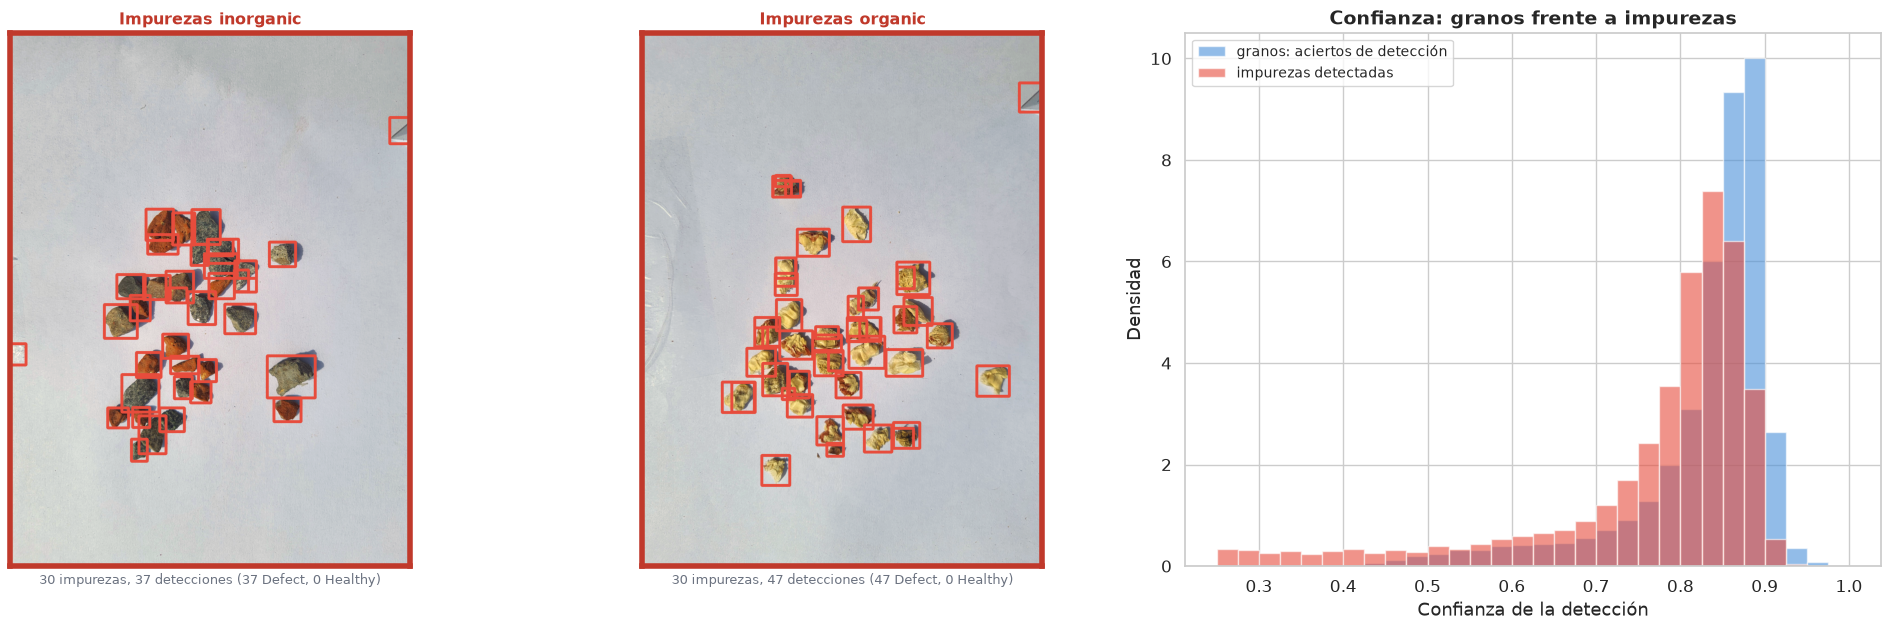

In [5]:
# ¿Separa el umbral de confianza las impurezas de los granos?
umbrales = [0.25, 0.4, 0.5, 0.6, 0.7, 0.8]
granos_c = conf[conf.tipo != 'impurezas'].conf
imp_c = conf[conf.tipo == 'impurezas'].conf
display(pd.DataFrame({'umbral': umbrales,
                      'aciertos de grano que se conservan': [(granos_c >= u).mean() for u in umbrales],
                      'detecciones de impurezas que se conservan': [(imp_c >= u).mean() for u in umbrales]}).set_index('umbral').round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for ax, tipo in zip(axes[:2], ('Inorganic', 'Organic')):
    stem, pb, pc = ejemplos[tipo]
    img = cv2.cvtColor(pre[stem][0], cv2.COLOR_BGR2RGB)
    vista = E.dibujar(E.dibujar(img, pb[pc == 0], E.CAJA_OK, 5), pb[pc == 1], E.CAJA_MAL, 5)
    E.mostrar(ax, vista, f'Impurezas {tipo.lower()}', f'{len(pre[stem][1])} impurezas, {len(pb)} detecciones '
              f'({(pc == 1).sum()} Defect, {(pc == 0).sum()} Healthy)', estado='mal')
bins = np.linspace(0.25, 1, 31)
axes[2].hist(granos_c, bins=bins, density=True, alpha=0.6, color='#4A90D9', label='granos: aciertos de detección')
axes[2].hist(imp_c, bins=bins, density=True, alpha=0.6, color='#E74C3C', label='impurezas detectadas')
axes[2].set_xlabel('Confianza de la detección'); axes[2].set_ylabel('Densidad'); axes[2].legend(fontsize=10)
axes[2].set_title('Confianza: granos frente a impurezas')
C.guardar(SALIDA, 'evidencia_impurezas.png')

## 3. Imágenes preprocesadas

Las 144 impurezas y las 25 hojas se llevan al formato del dataset con `comun.preprocesar`. Cada imagen guarda:
- `labels/<nombre>.txt` vacío: un fondo para Ultralytics;
- `impurezas/<nombre>.txt`: las cajas de las impurezas en formato YOLO, para medir en la evaluación final qué fracción se detecta como grano (vacío en las hojas).

In [6]:
shutil.rmtree(E.FONDOS, ignore_errors=True)
for sub in ('images', 'labels', 'impurezas'):
    (E.FONDOS / sub).mkdir(parents=True)
registros = {}
for r in impurezas:
    nombre = f"imp_{E.IMPUREZAS[r['clases'][0]].lower()}_{r['stem']}"
    img, esc, (dx, dy) = C.preprocesar(cv2.imread(str(r['img'])), RES, FOTO)
    H, W = img.shape[:2]
    b = r['xyxy'] * esc + [dx, dy, dx, dy]
    yolo = np.stack([(b[:, 0] + b[:, 2]) / 2 / W, (b[:, 1] + b[:, 3]) / 2 / H, (b[:, 2] - b[:, 0]) / W, (b[:, 3] - b[:, 1]) / H], 1)
    C.guardar_yolo(E.FONDOS / 'impurezas' / f'{nombre}.txt', yolo, r['clases'])
    cv2.imwrite(str(E.FONDOS / 'images' / f'{nombre}.jpg'), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    registros[nombre] = {'tipo': E.IMPUREZAS[r['clases'][0]], 'origen': r['stem'], 'lote': lote_imp[r['stem']],
                         'destino': destino_lote[lote_imp[r['stem']]]}
for p, d in destino_hoja.items():
    nombre = f'hoja_{p.stem.lower()}'
    img, _, _ = C.preprocesar(E.leer_hoja(p), RES, FOTO)
    (E.FONDOS / 'impurezas' / f'{nombre}.txt').write_text('')
    cv2.imwrite(str(E.FONDOS / 'images' / f'{nombre}.jpg'), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    registros[nombre] = {'tipo': 'hoja', 'origen': f'{p.parent.name}/{p.name}', 'lote': None, 'destino': d}
for nombre in registros:
    (E.FONDOS / 'labels' / f'{nombre}.txt').write_text('')
print(f'{len(registros)} imágenes en {E.FONDOS}')

169 imágenes en /home/ismael/Documents/Tesis/maiz-yolo11-v2/datos/fondos


## 4. Fondos de cada partición

Para cada partición de la Actividad 2.2 (`valid`: entrenamiento con los pliegues 0, 1 y 3 y validación con el 2; `p0` a `p3`: validación cruzada), se eligen:
- **entrenamiento:** las hojas de entrenamiento y, hasta completar el 10 %, impurezas de los lotes de entrenamiento de esa partición, mitad de cada tipo y una por lote por turnos;
- **medición:** todas las impurezas de los lotes de validación de esa partición y las hojas de medición.

La evaluación final usa las impurezas de los lotes del test y las hojas de evaluación.

In [7]:
pliegue_de = {s: v['pliegue'] for s, v in PART['imagenes'].items() if v['conjunto'] == 'dev'}
hojas_en = sorted(n for n, r in registros.items() if r['tipo'] == 'hoja' and r['destino'] == 'entrenamiento')
hojas_me = sorted(n for n, r in registros.items() if r['tipo'] == 'hoja' and r['destino'] == 'medicion')

def elegir(nombres, n, rng):
    # n impurezas, mitad de cada tipo, una por lote por turnos
    elegidas = []
    for t, tipo in enumerate(('Inorganic', 'Organic')):
        cupo = n // 2 + (t < n % 2)
        por_lote = defaultdict(list)
        for k in nombres:
            if registros[k]['tipo'] == tipo:
                por_lote[registros[k]['lote']].append(k)
        colas = [list(rng.permutation(sorted(v))) for _, v in sorted(por_lote.items())]
        tomadas = []
        while len(tomadas) < cupo and any(colas):
            for cola in colas:
                if cola and len(tomadas) < cupo:
                    tomadas.append(cola.pop())
        elegidas += tomadas
    return sorted(elegidas)

particiones, filas = {}, []
for particion, val in [('valid', E.PLIEGUE_VAL)] + [(f'p{k}', k) for k in range(PART['k'])]:
    n_granos = sum(1 for p in pliegue_de.values() if p != val)
    cupo = round(n_granos * FRACCION / (1 - FRACCION))
    entrenables = [n for n, r in registros.items() if r['tipo'] != 'hoja' and r['destino'] not in ('test', f'p{val}')]
    medibles = sorted(n for n, r in registros.items() if r['tipo'] != 'hoja' and r['destino'] == f'p{val}')
    imp = elegir(entrenables, cupo - len(hojas_en), np.random.default_rng(SEMILLA))
    particiones[particion] = {'entrenamiento': sorted(hojas_en + imp), 'medicion': sorted(medibles + hojas_me)}
    tipos = Counter(registros[n]['tipo'] for n in particiones[particion]['entrenamiento'])
    filas.append({'partición': particion, 'granos de entrenamiento': n_granos, 'fondos de entrenamiento': len(particiones[particion]['entrenamiento']),
                  'hojas': tipos['hoja'], 'inorgánicas': tipos['Inorganic'], 'orgánicas': tipos['Organic'],
                  'lotes de las impurezas': len({registros[n]['lote'] for n in imp}),
                  'fracción de fondos': round(len(particiones[particion]['entrenamiento']) / (n_granos + len(particiones[particion]['entrenamiento'])), 3),
                  'impurezas de medición': len(medibles), 'hojas de medición': len(hojas_me)})
evaluacion = sorted(n for n, r in registros.items() if r['destino'] in ('test', 'evaluacion'))
json.dump({'preprocesamiento': {'resolucion': RES, 'fotometrico': FOTO}, 'imagenes': registros, 'particiones': particiones,
           'evaluacion': evaluacion}, open(E.FONDOS / 'fondos.json', 'w'), indent=1, ensure_ascii=False)
display(pd.DataFrame(filas).set_index('partición'))
print(f"Evaluación final: {sum(registros[n]['tipo'] != 'hoja' for n in evaluacion)} impurezas de los lotes del test y "
      f"{sum(registros[n]['tipo'] == 'hoja' for n in evaluacion)} hojas")

,granos de entrenamiento,fondos de entrenamiento,hojas,inorgánicas,orgánicas,lotes de las impurezas,fracción de fondos,impurezas de medición,hojas de medición
partición,,,,,,,,,
valid,344,38,12,13,13,5,0.099,18,3
p0,339,38,12,13,13,6,0.101,34,3
p1,339,38,12,13,13,6,0.101,35,3
p2,344,38,12,13,13,5,0.099,18,3
p3,355,39,12,14,13,4,0.099,27,3


Evaluación final: 30 impurezas de los lotes del test y 10 hojas


## 5. Verificaciones

In [8]:
from ultralytics.data.dataset import YOLODataset

chequeos = []
def chequeo(nombre, ok, detalle=''):
    chequeos.append({'verificación': nombre, 'resultado': 'OK' if ok else 'FALLA', 'detalle': detalle})

tam = Counter(cv2.imread(str(p)).shape[:2] for p in (E.FONDOS / 'images').glob('*.jpg'))
chequeo(f'Lado mayor de {RES} px y ambos lados múltiplos de 32', all(max(t) == RES and t[0] % 32 == 0 and t[1] % 32 == 0 for t in tam),
        ', '.join(f'{w}×{h}: {n}' for (h, w), n in tam.most_common()))
chequeo('Etiquetas vacías (fondos)', all((E.FONDOS / 'labels' / f'{n}.txt').read_text() == '' for n in registros), f'{len(registros)} imágenes')
lotes_test = {v['lote'] for v in PART['imagenes'].values() if v['conjunto'] == 'test'}
dev_fondos = {registros[n]['lote'] for p in particiones.values() for k in p.values() for n in k if registros[n]['lote']}
chequeo('Ninguna impureza de los lotes del test fuera de la evaluación final', not dev_fondos & lotes_test)
ok = True
for particion, val in [('valid', E.PLIEGUE_VAL)] + [(f'p{k}', k) for k in range(PART['k'])]:
    lotes_val = {v['lote'] for v in PART['imagenes'].values() if v['conjunto'] == 'dev' and v['pliegue'] == val}
    ok &= not {registros[n]['lote'] for n in particiones[particion]['entrenamiento'] if registros[n]['lote']} & lotes_val
chequeo('Ningún fondo de entrenamiento comparte lote con la validación de su partición', ok)

carpeta = Path(E.TRABAJO) / 'verificacion'
yaml, val, medicion = E.datos_particion('valid', dict(E.REFERENCIA, fondos=True), carpeta)
ds = YOLODataset(img_path=str(Path(yaml).parent / 'train.txt'), data={'names': {0: 'Healthy', 1: 'Defect'}, 'nc': 2, 'channels': 3},
                 augment=False, imgsz=E.IMGSZ)
n_vacias = sum(len(l['cls']) == 0 for l in ds.labels)
chequeo('Ultralytics lee los fondos como imágenes sin cajas (partición valid)', n_vacias == len(particiones['valid']['entrenamiento']),
        f'{len(ds.labels)} imágenes de entrenamiento, {n_vacias} sin cajas ({n_vacias / len(ds.labels):.1%})')
shutil.rmtree(carpeta, ignore_errors=True)
pd.DataFrame(chequeos).set_index('verificación')

,resultado,detalle
verificación,,
Lado mayor de 1280 px y ambos lados múltiplos de 32,OK,"960×1280: 150, 1280×960: 19"
Etiquetas vacías (fondos),OK,169 imágenes
Ninguna impureza de los lotes del test fuera de la evaluación final,OK,
Ningún fondo de entrenamiento comparte lote con la validación de su partición,OK,
Ultralytics lee los fondos como imágenes sin cajas (partición valid),OK,"382 imágenes de entrenamiento, 38 sin cajas (9..."


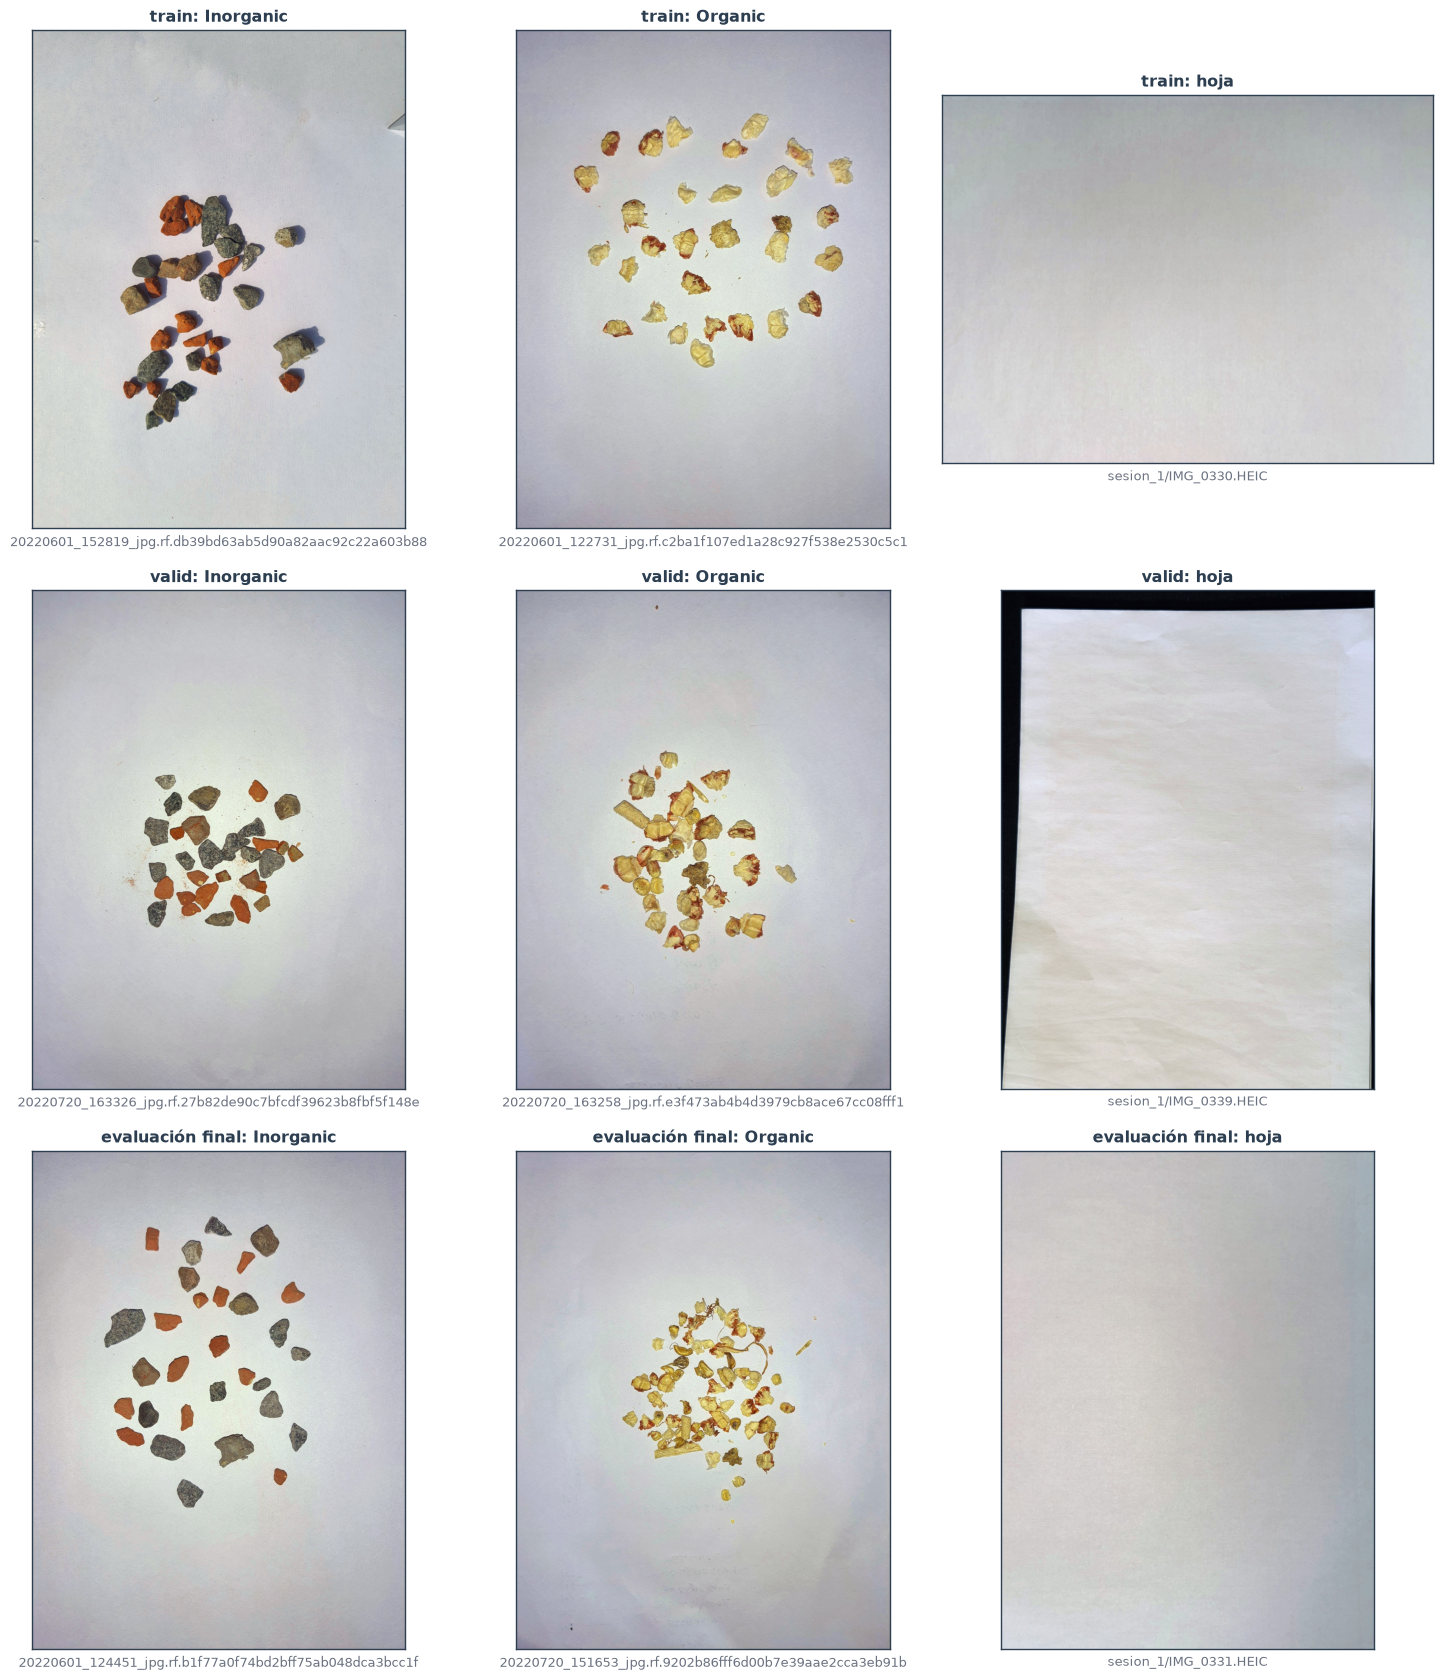

In [9]:
# Un ejemplo de cada tipo y destino
fig, axes = plt.subplots(3, 3, figsize=(15, 17))
for fila, destino in zip(axes, (('p0', 'p1', 'p3'), ('p2',), ('test',))):
    nombre_fila = {('p0', 'p1', 'p3'): 'train', ('p2',): 'valid', ('test',): 'evaluación final'}[destino]
    for ax, tipo in zip(fila, ('Inorganic', 'Organic', 'hoja')):
        if tipo == 'hoja':
            d = {'train': 'entrenamiento', 'valid': 'medicion', 'evaluación final': 'evaluacion'}[nombre_fila]
            n = next(k for k, r in sorted(registros.items()) if r['tipo'] == 'hoja' and r['destino'] == d)
        else:
            n = next(k for k, r in sorted(registros.items()) if r['tipo'] == tipo and r['destino'] in destino)
        img = cv2.cvtColor(cv2.imread(str(E.FONDOS / 'images' / f'{n}.jpg')), cv2.COLOR_BGR2RGB)
        E.mostrar(ax, img, f'{nombre_fila}: {tipo}', registros[n]['origen'])
C.guardar(SALIDA, 'ejemplos_fondos.png')

## 6. Paquete para la nube

Genera `nube/oe2_nube.zip` con lo necesario para correr `nube/2.2_entrenamiento_colab.ipynb` en Colab:
- el código (`oe1/comun.py`, `oe2/comun_oe2.py`), la partición y la decisión del OE1;
- `Data_final` y los fondos;
- el registro de corridas, si ya existe (la nube omite las corridas registradas).

Se sube a la raíz de Google Drive.

In [10]:
zip_nube = C.NUBE / 'oe2_nube.zip'
zip_nube.parent.mkdir(exist_ok=True)
archivos = [C.RAIZ / 'comun.py', C.RAIZ / 'resultados' / 'particion.json', C.RAIZ / 'resultados' / 'decision.json', RAIZ / 'comun_oe2.py']
archivos += sorted(E.REGISTRO.glob('*.csv'))
archivos += sorted(p for p in E.FINAL.rglob('*') if p.is_file() and not p.name.endswith('.cache'))
archivos += sorted(p for p in E.FONDOS.rglob('*') if p.is_file() and not p.name.endswith('.cache'))
import zipfile
with zipfile.ZipFile(zip_nube, 'w') as z:
    for p in archivos:
        z.write(p, Path(C.REPO.name) / p.relative_to(C.REPO), compress_type=zipfile.ZIP_STORED if p.suffix == '.jpg' else zipfile.ZIP_DEFLATED)
print(f'{zip_nube} ({zip_nube.stat().st_size / 1e6:.0f} MB, {len(archivos)} archivos)')

/home/ismael/Documents/Tesis/maiz-yolo11-v2/nube/oe2_nube.zip (223 MB, 2055 archivos)
